# Exploratory analysis — Geneva (A) and Zurich (B)

Inside Airbnb `listings.csv`, Switzerland, prices in CHF. City C (Vaud) is not loaded here — it stays unseen until week 2.

## Summary

**What we know**
- One row = one listing. Geneva (A): 2,538 listings, snapshot 2026-09-23. Zurich (B): 3,174 listings, snapshot 2026-09-25.
- 30–34% of listings have **no price**, and these are almost all inactive listings (calendar closed all year). The model can only learn from active, priced listings.
- Prices are right-skewed: median CHF 154 in Geneva, CHF 185 in Zurich; log price is roughly bell-shaped, so we model log price.
- 13 listings have implausible prices (e.g. CHF 11,382 for one guest) and are excluded from training; 26 expensive but real listings are kept.
- **Leaks:** `price_quote_*` is the price itself, `estimated_revenue_l365d` is price × occupancy. Availability, occupancy and recent-review columns are outcomes of the price. None of these may be features.
- Review scores are missing only for listings without reviews.

**What we still don't know**
- Whether a listing with low availability is popular or simply blocked by the host.
- Whether the listed price is what guests actually pay (cleaning fees, discounts and seasonal prices are not in this file).
- Whether inactive listings would be priced like active ones — the model says nothing about them.
- How well these patterns hold in a new city: Zurich has neighbourhood groups that Geneva lacks, so column coverage already differs between cities.

In [1]:
import os, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.insert(0, os.path.join(REPO_ROOT, "src"))
from bda.config import cities_by_role, get_city, volume_csv_path

def load(city_key):
    """Databricks: read the volume filled by 00_setup. Locally: read data/ from the repo."""
    try:
        df = (spark.read.option("header", True).option("multiLine", True).option("escape", '"')
              .csv(volume_csv_path(city_key)).toPandas())
    except NameError:
        df = pd.read_csv(os.path.join(REPO_ROOT, get_city(city_key)["raw_path"]), dtype=str)
    df.insert(0, "city", get_city(city_key)["name"])
    return df

raw = pd.concat([load(c) for c in cities_by_role("train")], ignore_index=True)
raw.shape

(5712, 91)

## 1. Dataset

In [2]:
raw.groupby("city").agg(
    rows=("id", "size"),
    unique_listings=("id", "nunique"),
    hosts=("host_id", "nunique"),
    scraped_from=("last_scraped", "min"),
    scraped_to=("last_scraped", "max"),
).assign(snapshot_date=[get_city(c)["snapshot_date"] for c in cities_by_role("train")])

,rows,unique_listings,hosts,scraped_from,scraped_to,snapshot_date
city,,,,,,
Geneva,2538,2538,1617,2026-09-25,2026-09-26,2026-09-23
Zurich,3174,3174,1586,2026-09-26,2026-09-27,2026-09-25


- **Grain: one row = one listing** on the snapshot date (`id` is unique in each city).
- **Record counts:** Geneva 2,538 listings, Zurich 3,174.
- The published snapshot date (README) is 1–2 days before the rows were actually scraped.

## 2. Columns we use

Everything arrives as text. We keep the columns that describe a listing, its availability and its reviews, and convert them to proper types.

In [3]:
NUMERIC = ["accommodates", "bedrooms", "beds", "minimum_nights", "availability_30", "availability_365",
           "number_of_reviews", "review_scores_rating", "calculated_host_listings_count", "latitude", "longitude"]
CATEGORICAL = ["room_type", "property_type", "neighbourhood_cleansed", "neighbourhood_group_cleansed", "host_is_superhost"]

df = raw[["city", "id"] + CATEGORICAL].copy()
df["price"] = pd.to_numeric(raw["price"].str.replace(r"[$,]", "", regex=True))   # "$1,025.00" -> 1025.0
df["bathrooms"] = pd.to_numeric(raw["bathrooms_text"].str.extract(r"([\d.]+)")[0])  # "1.5 shared baths" -> 1.5
df[NUMERIC] = raw[NUMERIC].apply(pd.to_numeric)
df["last_review"] = pd.to_datetime(raw["last_review"])

missing = df.groupby("city").agg(lambda s: s.isna().mean() * 100).T.round(1)
missing.insert(0, "type", df.dtypes.astype(str))
missing[missing[["Geneva", "Zurich"]].sum(axis=1) > 0]

city,type,Geneva,Zurich
neighbourhood_group_cleansed,str,100.0,0.0
price,float64,29.7,34.1
bathrooms,float64,1.8,2.0
beds,float64,2.9,2.0
minimum_nights,float64,0.7,0.3
review_scores_rating,float64,19.3,22.9
last_review,datetime64[us],19.3,22.9


### Why values are missing

In [4]:
# Fix: "Half-bath" / "Shared half-bath" have no digit -> 0.5
df.loc[raw["bathrooms_text"].str.contains("half", case=False, na=False), "bathrooms"] = 0.5
print(f"bathrooms missing after fix: {df['bathrooms'].isna().mean():.1%}")

# Reviews: missing review scores vs listings with no reviews at all
print(pd.crosstab(df["number_of_reviews"] == 0, df["review_scores_rating"].isna(),
                  rownames=["no reviews"], colnames=["score missing"]))

# Price: share missing for listings whose calendar is fully closed vs open
df["calendar_closed"] = df["availability_365"] == 0
print((df.groupby(["city", "calendar_closed"])["price"].apply(lambda s: s.isna().mean() * 100)
       .round(1).unstack().rename(columns={False: "% no price (open)", True: "% no price (closed)"})))

bathrooms missing after fix: 0.2%
score missing  False  True 
no reviews                 
False           4495      0
True               0   1217
calendar_closed  % no price (open)  % no price (closed)
city                                                   
Geneva                         5.9                 97.6
Zurich                         9.8                 98.8


- **Review scores** are missing exactly for listings with no reviews yet — expected, not a data problem.
- **Price** is missing for 30–34% of listings, and almost only for listings whose calendar is fully closed (`availability_365 = 0`: 98% have no price vs 6–10% of open ones). These are inactive listings: Airbnb returns no price when nothing can be booked. We do not impute the target; the model is trained on listings with a price.
- `neighbourhood_group_cleansed` is empty in Geneva but filled in Zurich (`Kreis 1–12`) — we use `neighbourhood_cleansed`, which exists in both.

## 3. Price

         count   mean    std   min    50%     99%      max
city                                                      
Geneva  1784.0  214.0  533.0  28.0  154.0  1053.0  20541.0
Zurich  2091.0  239.0  342.0  36.0  185.0  1196.0  11382.0


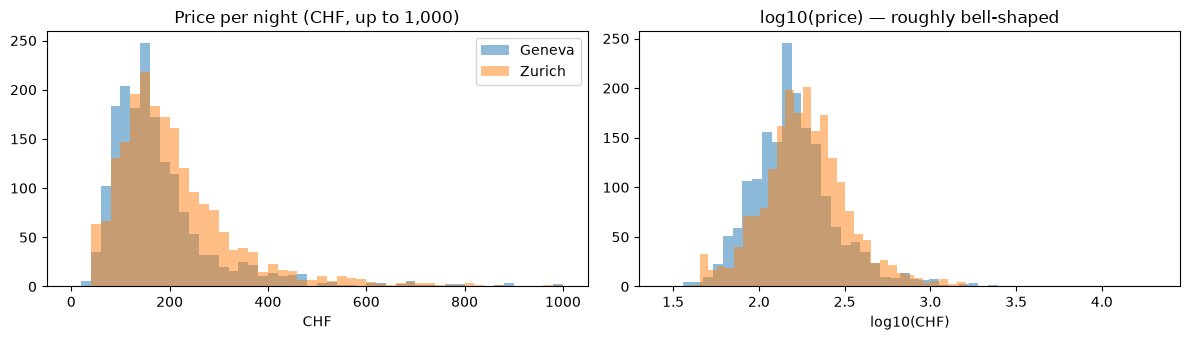

In [5]:
priced = df[df["price"].notna()]
print(priced.groupby("city")["price"].describe(percentiles=[.5, .99]).round(0))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for city, g in priced.groupby("city"):
    ax[0].hist(g["price"], bins=np.arange(0, 1001, 20), alpha=.5, label=city)
    ax[1].hist(np.log10(g["price"]), bins=50, alpha=.5, label=city)
ax[0].set(title="Price per night (CHF, up to 1,000)", xlabel="CHF")
ax[1].set(title="log10(price) — roughly bell-shaped", xlabel="log10(CHF)")
ax[0].legend(); plt.tight_layout(); plt.show()

### Outliers

Price alone is a poor outlier test: a CHF 1,500 villa for 10 people is normal, a CHF 1,500 single room is not. We look at **price per guest**.

In [6]:
priced = priced.assign(price_per_guest=priced["price"] / priced["accommodates"])
cols = ["city", "room_type", "property_type", "accommodates", "price", "price_per_guest", "number_of_reviews"]
print(priced.nlargest(12, "price_per_guest")[cols].round(0).to_string(index=False))
print("\nprice_per_guest percentiles:", priced["price_per_guest"].quantile([.5, .95, .99]).round(0).to_dict())

  city       room_type               property_type  accommodates   price  price_per_guest  number_of_reviews
Zurich    Private room Private room in rental unit             1 11382.0          11382.0                  4
Geneva Entire home/apt                Entire villa             6 20541.0           3424.0                  0
Zurich    Private room Private room in rental unit             1  1204.0           1204.0                  8
Zurich Entire home/apt          Entire rental unit             1  1021.0           1021.0                  0
Geneva Entire home/apt                 Entire home             2  1950.0            975.0                  0
Zurich    Private room Private room in rental unit             4  3652.0            913.0                  0
Zurich    Private room               Room in hotel             2  1456.0            728.0                  0
Zurich Entire home/apt                Entire condo             2  1448.0            724.0                  0
Zurich    Private r

In [7]:
def outlier_class(d):
    return np.select(
        [(d["price_per_guest"] > 500) & (d["number_of_reviews"] < 10),   # nobody books at this price
         d["price_per_guest"] > d["price_per_guest"].quantile(.99)],     # expensive but booked / large
        ["implausible", "high_end"], default="normal")

priced = priced.assign(outlier=outlier_class(priced))
pd.crosstab(priced["outlier"], priced["city"])

city,Geneva,Zurich
outlier,,
high_end,8,18
implausible,4,9
normal,1772,2064


- **Implausible** (13 listings): over CHF 500 per guest per night with fewer than 10 reviews ever — e.g. a single room at CHF 11,382. Placeholder or "don't book me" prices. **Excluded from training**, kept in the data with a flag.
- **High end** (26): top 1% price per guest but booked or large (villas, premium flats). Real prices — **kept**; modelling log price limits their influence.
- No low-end outliers: the cheapest listings (CHF 28–50 for shared/private rooms) are plausible.

## 4. Availability

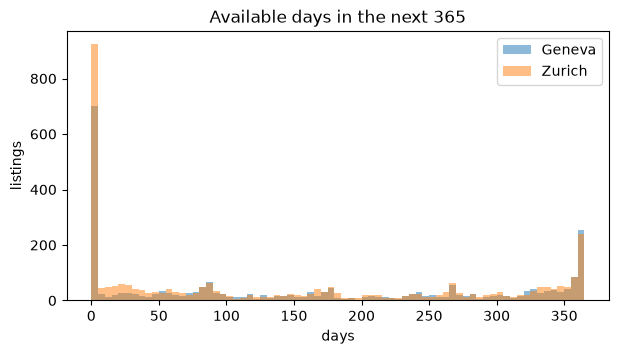

,median_days_open,pct_closed_all_year,pct_open_all_year
city,,,
Geneva,122.0,26.0,3.3
Zurich,88.0,27.3,2.7


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for city, g in df.groupby("city"):
    ax.hist(g["availability_365"], bins=73, alpha=.5, label=city)
ax.set(title="Available days in the next 365", xlabel="days", ylabel="listings"); ax.legend(); plt.show()

df.groupby("city").agg(
    median_days_open=("availability_365", "median"),
    pct_closed_all_year=("calendar_closed", lambda s: round(s.mean() * 100, 1)),
    pct_open_all_year=("availability_365", lambda s: round((s == 365).mean() * 100, 1)),
)

About a quarter of listings are closed all year (the same listings that have no price). Availability counts days that are *neither booked nor blocked*, so low availability can mean "popular" or "host closed it" — we cannot tell which. It is a dashboard metric, not a model feature.

## 5. Leakage review

Which columns must not be used to predict price? We test the suspicious ones against `price` directly.

In [9]:
num = lambda c: pd.to_numeric(raw[c])
p = df["price"]
has_p = p.notna()

checks = {
    "price_quote_price_per_night == price":        np.isclose(num("price_quote_price_per_night"), p)[has_p].mean(),
    "estimated_revenue_l365d == price × occupancy": np.isclose(num("estimated_revenue_l365d"),
                                                               p * num("estimated_occupancy_l365d"), atol=1)[has_p].mean(),
    "price_quote_total_price missing iff price missing": (num("price_quote_total_price").isna() == p.isna()).mean(),
}
pd.Series(checks, name="share of listings").map("{:.1%}".format).to_frame()

,share of listings
price_quote_price_per_night == price,100.0%
estimated_revenue_l365d == price × occupancy,100.0%
price_quote_total_price missing iff price missing,100.0%


| Column | Why it must not be used |
|---|---|
| `price_quote_price_per_night` | **is the price** (identical in 100% of listings) |
| `price_quote_total_price`, `price_quote_raw` | the price × number of nights of a test booking; the JSON contains the price |
| `price_quote_checkin_date`, `price_quote_checkout_date` | only exist when a price was quoted — reveal whether the target exists |
| `estimated_revenue_l365d` | **computed as price × estimated occupancy** (100% match) |
| `estimated_occupancy_l365d`, `availability_*` | outcomes of the price (how much gets booked at that price), not inputs a host sets |
| `number_of_reviews_ltm`, `reviews_per_month`, `review_scores_value` | also partly outcomes of the price (demand, "value for money"); excluded to be safe |

Allowed: what a host decides when setting up the listing — room type, property type, accommodates, bedrooms, beds, bathrooms, neighbourhood, location, minimum nights — plus host and long-run review history (`number_of_reviews`, `review_scores_rating`).

## 6. Cleaning the pipeline must apply

| Step | Reason |
|---|---|
| Read CSV with `multiLine` and `escape='"'` | descriptions contain line breaks and quotes; otherwise rows split |
| `price`: strip `$` and `,`, cast to double | stored as text like `"$1,025.00"`; the `$` is a display artefact, the currency is CHF |
| `bathrooms` from `bathrooms_text` (`Half-bath` → 0.5); flag `shared` | the `bathrooms` column is empty |
| Cast numbers, `t`/`f` booleans, dates | everything arrives as text |
| Keep listings without price, flag `has_price = false`; train only on priced ones | missing price = inactive listing; imputing the target would invent data |
| Flag `implausible` outliers and exclude them from training | placeholder prices nobody books at would distort the model |
| Use `neighbourhood_cleansed`, not `neighbourhood_group_cleansed` | the group is empty in Geneva |
| Drop the leakage columns above before building features | they are computed from or caused by the price |
| Add `city` and `snapshot_date` to every row | one table holds all cities |